In [1]:
%matplotlib inline
%config InlineBackend.figure_format='retina'

import warnings
# Ignore warning for ligo.skymap
warnings.filterwarnings('ignore', 'Wswiglal-redir-stdio')

import astropy.units as u
import ligo.skymap.plot
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import sys
# import uvex

from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import QTable, Table
from astropy.units import UnitsWarning

sys.path.append(os.path.join(os.path.expanduser('~/Desktop'), 'github'))
from my_style import setup, clear_plt, get_dir

_info           = setup()
current_date    = _info['current_date']
dir_desktop     = _info['dir_desktop']

dir_gaia    = get_dir('uvex-sim', 'gaia-data')
dir_uvgaps  = get_dir('uvex-sim', 'uvgaps-data')
dir_plots   = get_dir('uvex-sim', 'plots')

In [2]:
from astroquery.svo_fps import SvoFps
from dust_extinction.parameter_averages import G23
from dustmaps.bayestar import BayestarQuery # Green+19; # NOTE: decl > -30
from synphot import ExtinctionCurve, Observation, SourceSpectrum, SpectralElement, units
from synphot.models import BlackBodyNorm1D, Empirical1D

sys.path.append(os.path.join(os.path.expanduser('~/Desktop'), 'github/uvex-source-lookup'))
from approx_spectra import (BANDS,
                            load_bandpass, reddened_blackbody, synthetic_mags,
                            mag_err, build_mag_grid, fit_teff_ebv,
                            make_inputs, save_inputs, load_inputs)

bayestar = BayestarQuery(version='bayestar2019')

Loading pixel_info ...
Loading samples ...
Loading best_fit ...
Replacing NaNs in reliable distance estimates ...
Sorting pixel_info ...
Extracting hp_idx_sorted and data_idx at each nside ...
  nside = 64
  nside = 128
  nside = 256
  nside = 512
  nside = 1024
t = 23.095 s
  pix_info:   0.289 s
   samples:  11.492 s
      best:   2.216 s
       nan:   0.034 s
      sort:   9.018 s
       idx:   0.046 s


In [5]:
wave = np.arange(1000.0, 12000.0, 5) * u.AA
ext_model = G23(Rv=3.1)
vega = SourceSpectrum.from_vega()

bandpasses = {name: load_bandpass(svo_id) for name, (svo_id, _) in BANDS.items()}

teff_grid = np.geomspace(3000.0, 40000.0, 50)
ebv_grid = np.arange(0.0, 3.01, 0.05)

mag_grid = build_mag_grid(teff_grid, ebv_grid, bandpasses, vega, wave, ext_model)

  points: [10987.5 10990. ]
  lookup_table: [-2.97498e-05 -1.87648e-04] [synphot.models]


## Load in fov table

### Most populated UVEX FoV

In [5]:
# Columbia Galactic plane catalog (Galex + Gaia) data matched to UVEX FoVs
file_plane = 'uvex_fovs_plane_gaiadr2_dust_2026_10_11.fits'
table_plane = Table.read(os.path.join(dir_uvgaps, file_plane))
# table_plane.pprint(max_width=-1)

# Most populated field
table_field = table_plane[table_plane['field_id']==int(4996)]
table_field.pprint(max_width=-1)

field_id                 center                    solution_id          source_id           ra_gaia             ra_error             dec_gaia           dec_error             parallax         parallax_error            pmra               pmdec         visibility_periods_used duplicated_source  phot_g_mean_flux  phot_g_mean_flux_error  phot_g_mean_mag   phot_bp_mean_flux  phot_bp_mean_flux_error  phot_bp_mean_mag  phot_rp_mean_flux  phot_rp_mean_flux_error  phot_rp_mean_mag    radial_velocity   radial_velocity_error rv_template_teff rv_template_logg rv_template_fe_h phot_variable_flag     teff_val         flame_flags              angsep         number_plane NUMBER      X_IMAGE           Y_IMAGE        ra_plane     dec_plane    FLUX_AUTO FLUXERR_AUTO FLUX_APER A_IMAGE B_IMAGE  THETA_IMAGE FWHM_IMAGE        nuv               gl            gb             expsum       ctsum       bkgdsum               dist             distmod               ebv         
                        deg,deg         

In [6]:
table_field.write(os.path.join(dir_uvgaps, 'UVEXfov4996_gaia_galex.fits'))

### Other fields

In [43]:
file_field = os.path.join(dir_uvgaps, 'h_and_chi_Persei_gaia_ps2_2026_10_11.fits')
table_field = Table.read(file_field)
table_field.pprint(max_width=-1)

    field_id             center         plane_number NUMBER      X_IMAGE           Y_IMAGE       ALPHA_J2000   DELTA_J2000  FLUX_AUTO FLUXERR_AUTO FLUX_APER A_IMAGE B_IMAGE  THETA_IMAGE FWHM_IMAGE        nuv               gl            gb             expsum       ctsum        bkgdsum        objid        ra           dec           Column1          raMean     decMean   nDetections  ng  nr  ni  nz  ny    gMeanPSFMag        rMeanPSFMag        iMeanPSFMag        zMeanPSFMag        yMeanPSFMag           angsep_1          solution_id         source_id           ra_gaia             ra_error            dec_gaia           dec_error             parallax         parallax_error            pmra               pmdec         visibility_periods_used duplicated_source  phot_g_mean_flux  phot_g_mean_flux_error  phot_g_mean_mag   phot_bp_mean_flux  phot_bp_mean_flux_error  phot_bp_mean_mag  phot_rp_mean_flux  phot_rp_mean_flux_error  phot_rp_mean_mag    radial_velocity   radial_velocity_error rv_template_t

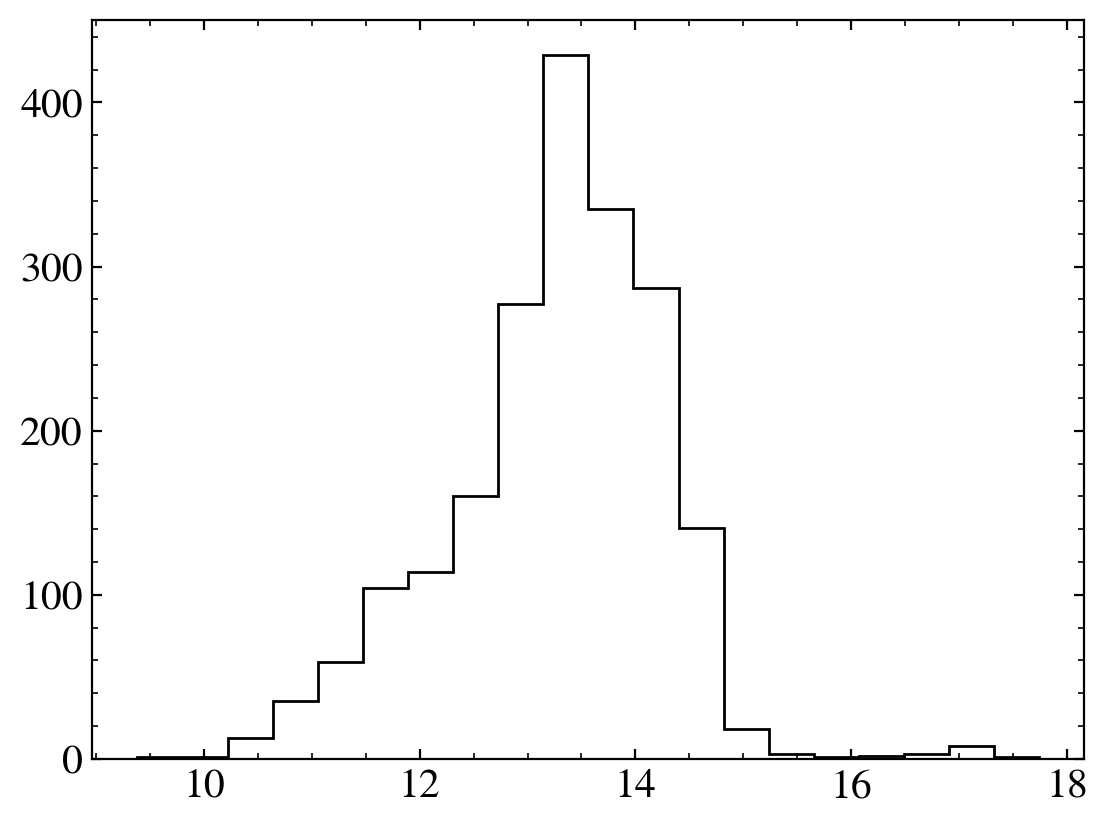

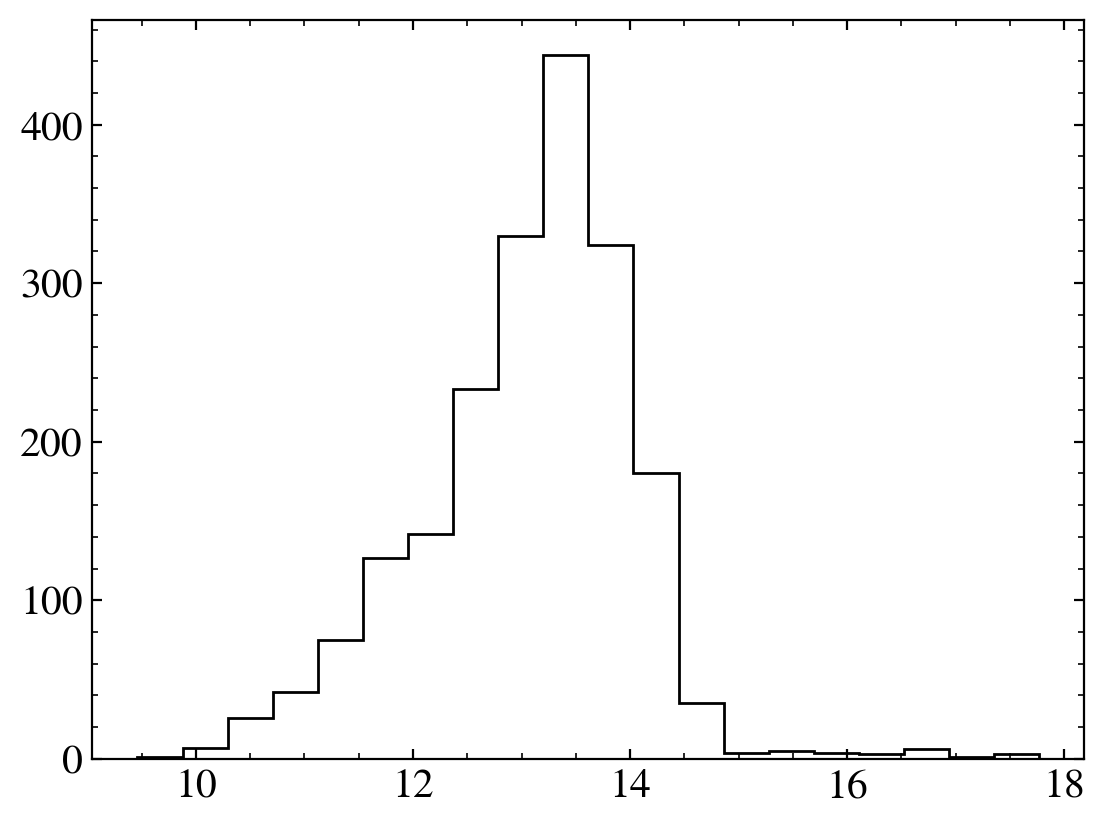

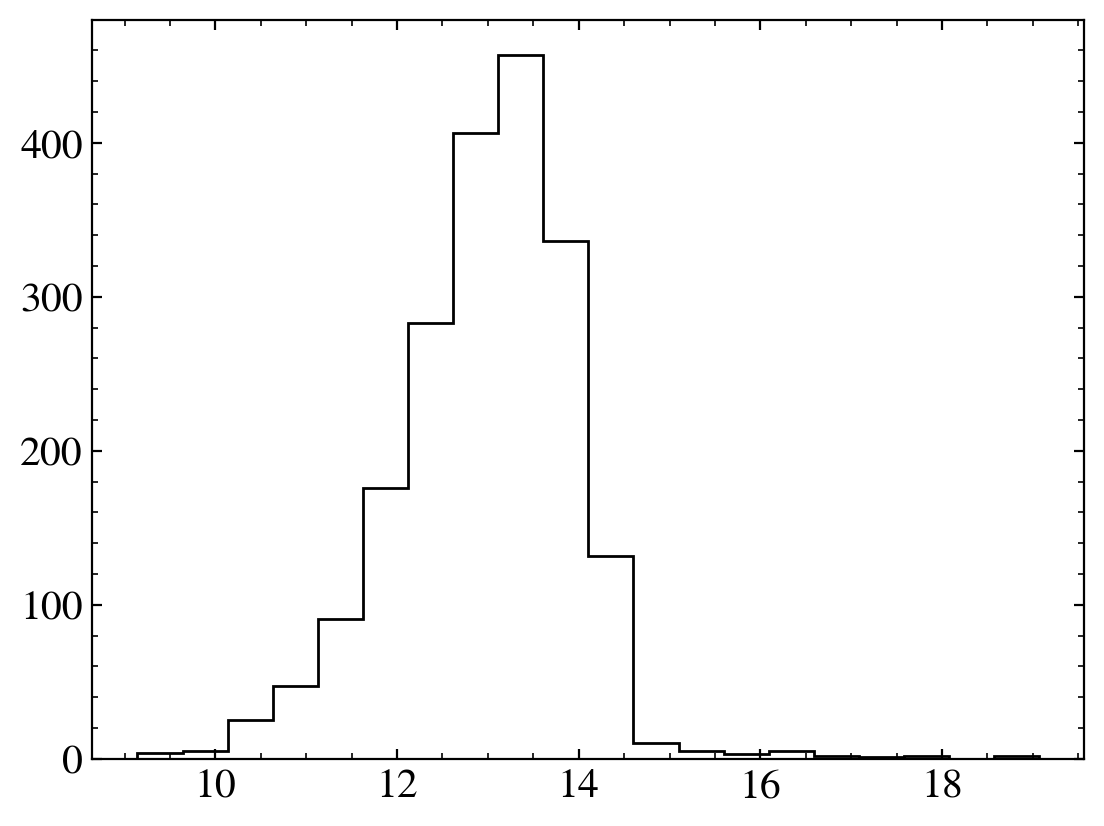

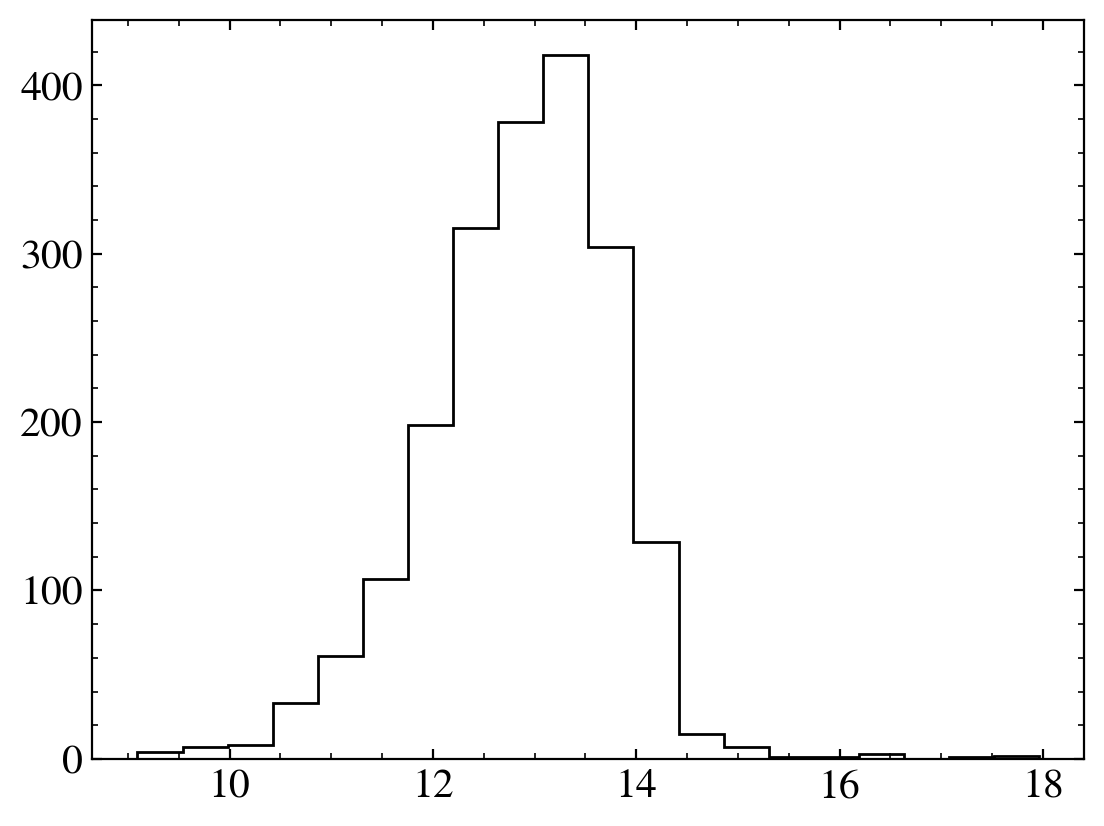

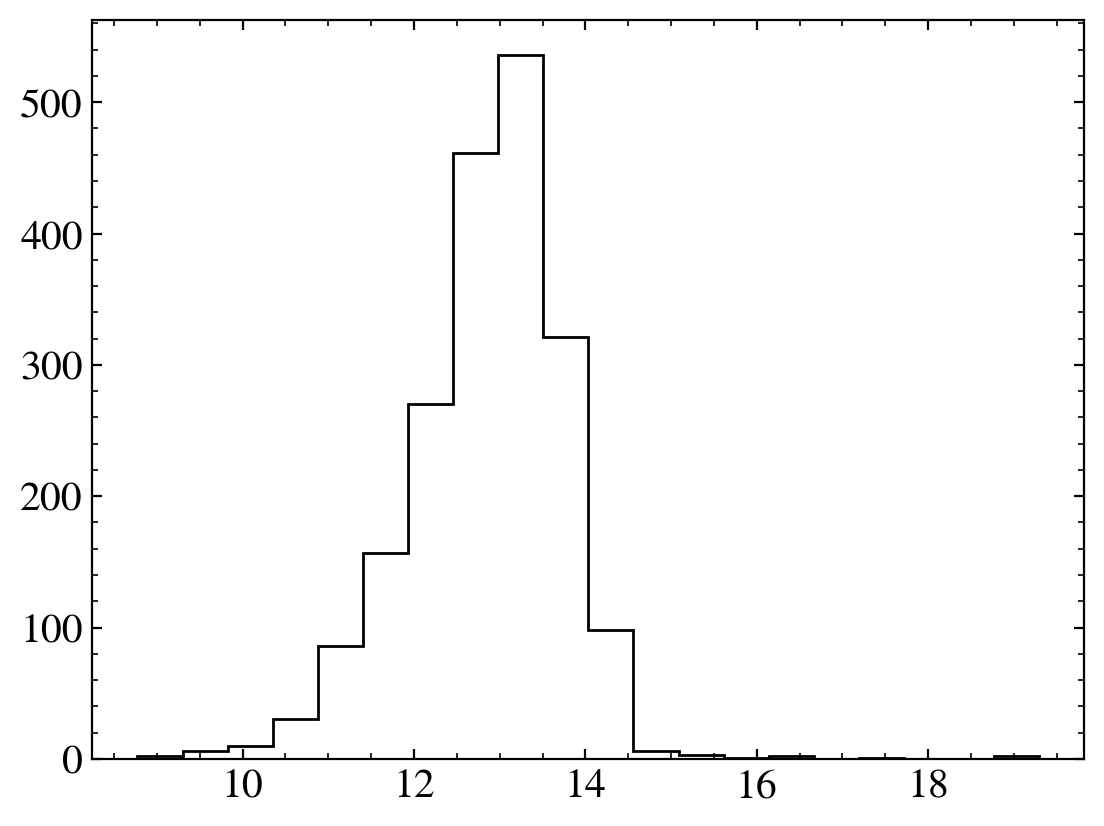

In [24]:
ps_bandpasses = ['g', 'r', 'i', 'z', 'y']
ps_mag_cols = [f'{b}MeanPSFMag' for b in ps_bandpasses]
for col in ps_mag_cols:
    plt.figure()
    plt.hist(table_field[col], bins=20, histtype='step', color='black')
    plt.show()
    clear_plt()

## Approximate spectra

In [ ]:
# Reddening prior
plx = np.asarray(table_field['parallax']) + 0.029 # NOTE: # DR2 zero-point correction [mas] from Lindegren+18
plx_snr = plx / np.asarray(table_field['parallax_error'])
dist_pc = 1000.0 / plx

coord_gal = SkyCoord(l=np.asarray(table_field['gl'])*u.deg,
                     b=np.asarray(table_field['gb'])*u.deg,
                     distance=dist_pc*u.pc, frame='galactic')

ebv_pct = bayestar(coord_gal, mode='percentile', pct=[16, 50, 84])
p16, p50, p84 = ebv_pct.T
to_ebv = 0.884 # NOTE: CHECK VALUE; conversion for compatibility with SFD
ebv_priors = to_ebv * p50
ebv_prior_errs = np.hypot(to_ebv * (p84 - p16)/2, 0.05)

In [45]:
ps_bandpasses = ['g', 'r', 'i', 'z', 'y']
ps_mag_cols = [f'{b}MeanPSFMag' for b in ps_bandpasses]

gaia_bandpasses = ['g', 'bp', 'rp']
gaia_mag_cols = [f'phot_{b}_mean_mag' for b in gaia_bandpasses]

mag_cols = ['nuv'] + gaia_mag_cols + ps_mag_cols

obs_mag_all = np.column_stack([table_field[c] for c in mag_cols])

nuv_snr = np.asarray(table_field['FLUX_AUTO']/table_field['FLUXERR_AUTO'])

gaia_snr = [np.asarray(table_field[f'phot_{b}_mean_flux']/table_field[f'phot_{b}_mean_flux_error'])
            for b in gaia_bandpasses]

ps_err = [np.full(len(table_field), 0.05) for _ in ps_bandpasses]

obs_mag_err_all = np.column_stack([mag_err(flux_snr=nuv_snr, floor=0.1)]
                                  + [mag_err(flux_snr=s, floor=0.03) for s in gaia_snr]
                                  + ps_err)

# ps = slice(4, 9)
# bad_ps = (obs_mag_all[:, ps] <= -999)
# print(bad_ps)
# obs_mag_all[:, ps][bad_ps] = np.nan
# obs_mag_err_all[:, ps][bad_ps] = np.nan

In [46]:
n_row = len(table_field)

i_fit = np.full(n_row, -1) # -1 == not fitted
j_fit = np.full(n_row, -1)
offset_fit = np.full(n_row, np.nan)
chi2_min = np.full(n_row, np.nan)

for k in range(n_row):
    n_finite = np.sum(np.isfinite(obs_mag_all[k]) & np.isfinite(obs_mag_err_all[k]))
    if n_finite < 3: # skip source with < 3 bands; modify later to account for sources with missing bands
        continue
    use_prior = (np.isfinite(ebv_priors) & np.isfinite(ebv_prior_errs)
                 & (plx_snr > 5))
    if use_prior[k]:
        i, j, off, chi2 = fit_teff_ebv(obs_mag_all[k], obs_mag_err_all[k], mag_grid,
                                    ebv_grid, ebv_priors[k], ebv_prior_errs[k])
    else:
        i, j, off, chi2 = fit_teff_ebv(obs_mag_all[k], obs_mag_err_all[k], mag_grid)
    i_fit[k], j_fit[k], offset_fit[k], chi2_min[k] = i, j, off, chi2[i, j]

fitted = (i_fit >= 0) & (j_fit >= 0)
tbl_fov_fit = table_field.copy()
tbl_fov_fit['teff_fit'] = np.where(fitted, teff_grid[i_fit], np.nan)
tbl_fov_fit['ebv_fit'] = np.where(fitted, ebv_grid[j_fit], np.nan)
tbl_fov_fit['flux_scale_fit'] = 10.0 ** (-0.4 * offset_fit)
tbl_fov_fit['chi2_fit'] = chi2_min

nodes, node_counts = np.unique(np.column_stack([i_fit[fitted], j_fit[fitted]]),
                               axis=0, return_counts=True)

print(f'{fitted.sum()} sources fitted; {len(nodes)} distinct spectral shapes')
tbl_fov_fit.pprint(max_width=-1)

6199 sources fitted; 276 distinct spectral shapes
    field_id             center         plane_number NUMBER      X_IMAGE           Y_IMAGE       ALPHA_J2000   DELTA_J2000  FLUX_AUTO FLUXERR_AUTO FLUX_APER A_IMAGE B_IMAGE  THETA_IMAGE FWHM_IMAGE        nuv               gl            gb             expsum       ctsum        bkgdsum        objid        ra           dec           Column1          raMean     decMean   nDetections  ng  nr  ni  nz  ny    gMeanPSFMag        rMeanPSFMag        iMeanPSFMag        zMeanPSFMag        yMeanPSFMag           angsep_1          solution_id         source_id           ra_gaia             ra_error            dec_gaia           dec_error             parallax         parallax_error            pmra               pmdec         visibility_periods_used duplicated_source  phot_g_mean_flux  phot_g_mean_flux_error  phot_g_mean_mag   phot_bp_mean_flux  phot_bp_mean_flux_error  phot_bp_mean_mag  phot_rp_mean_flux  phot_rp_mean_flux_error  phot_rp_mean_mag    rad

In [47]:
point_sources_from_spectra, spectra = make_inputs(
    np.asarray(tbl_fov_fit['ra_gaia'])*u.deg,
    np.asarray(tbl_fov_fit['dec_gaia'])*u.deg,
    i_fit, j_fit,
    np.asarray(tbl_fov_fit['flux_scale_fit']),
    teff_grid, ebv_grid, wave, ext_model
)
fitted = (i_fit >= 0) & (j_fit >= 0) & np.isfinite(np.asarray(tbl_fov_fit['flux_scale_fit']))
point_sources_from_spectra.meta['source_id'] = np.asarray(tbl_fov_fit['source_id'])[fitted]
print(f'{len(point_sources_from_spectra):,} sources, {len(spectra):,} spectra')

refs_used, n_per_ref = np.unique(point_sources_from_spectra['ref'], return_counts=True)
order = np.argsort(n_per_ref)[::-1]
print('Top 10:', list(zip(refs_used[order][:10], n_per_ref[order][:10])))
print(f'Spectra shapes used by only 1 source: {np.sum(n_per_ref == 1):,}')
print(f'Spectra shapes covering 90% of sources: '
      f'{np.searchsorted(np.cumsum(n_per_ref[order]), 0.9 * len(point_sources_from_spectra)) + 1:,}')
point_sources_from_spectra.pprint(max_width=-1)

6,199 sources, 276 spectra
Top 10: [(np.str_('BB_T5965_E0.150'), np.int64(168)), (np.str_('BB_T6630_E0.200'), np.int64(143)), (np.str_('BB_T6288_E0.150'), np.int64(133)), (np.str_('BB_T6288_E0.200'), np.int64(128)), (np.str_('BB_T5965_E0.200'), np.int64(127)), (np.str_('BB_T6990_E0.200'), np.int64(104)), (np.str_('BB_T7369_E0.200'), np.int64(103)), (np.str_('BB_T5657_E0.150'), np.int64(99)), (np.str_('BB_T5965_E0.100'), np.int64(95)), (np.str_('BB_T6630_E0.150'), np.int64(95))]
Spectra shapes used by only 1 source: 71
Spectra shapes covering 90% of sources: 111
        ra                dec               ref              scale       
       deg                deg                                            
------------------ ------------------ ---------------- ------------------
 35.82703614475052  55.43794834627098  BB_T6288_E0.150  3.629804560406192
 34.80904533994875 55.448961961452895  BB_T5657_E0.150  3.743768989011951
 35.58706192539716  55.44382478729452  BB_T5657_E0.150 12.8424

In [48]:
file = os.path.join(dir_uvgaps, f'h_and_chi_Persei_gaia_galex_ps_inputs_{current_date}.fits')
save_inputs(file, point_sources_from_spectra, spectra, wave, overwrite=True)

point_sources_in, spectra_in = load_inputs(file)
print(point_sources_in.colnames, point_sources_in.masked, len(spectra_in))

['ra', 'dec', 'ref', 'scale'] False 276


In [49]:
test = Table.read(file, hdu='SOURCES')
test.pprint(max_width=-1)

        ra                dec               ref              scale            source_id     
       deg                deg                                                               
------------------ ------------------ ---------------- ------------------ ------------------
 35.82703614475052  55.43794834627098  BB_T6288_E0.150  3.629804560406192 455918754234025600
 34.80904533994875 55.448961961452895  BB_T5657_E0.150  3.743768989011951 455954076045674752
 35.58706192539716  55.44382478729452  BB_T5657_E0.150 12.842467221431452 455964933723777280
  35.7453201674151  55.44154808409799  BB_T6630_E0.150 3.5782830751475148 455965449119839616
  35.7030216762801  55.44363133433862  BB_T5366_E0.050  26.45334942814122 455965483479581696
  35.7532661200843  55.47084319195195  BB_T6630_E0.200    5.0529380545996 455965930156149376
 35.76621683159642  55.50974833361103  BB_T5965_E0.100 3.3779831025791203 455966067595062784
 35.72810875893894  55.49407750648434  BB_T6630_E0.150  4.678921530081

## Plots

### Random source

row 1496, source_id 457348669106884096, NUV ~18.96
Teff = 6288 K, E(B-V) = 0.15, chi2 = 36.45
model - observed [mag]: [-0.50241631 -0.06188169  0.05060776 -0.03062256  0.15038822  0.06350101
  0.00664124 -0.02905832  0.00684318]
[-3.14803425e-16 -2.56741972e-16  2.63059383e-16 -1.14770318e-16
  8.64359832e-16  3.30283714e-16  2.74926179e-17 -9.53086792e-17
  1.94398402e-17]


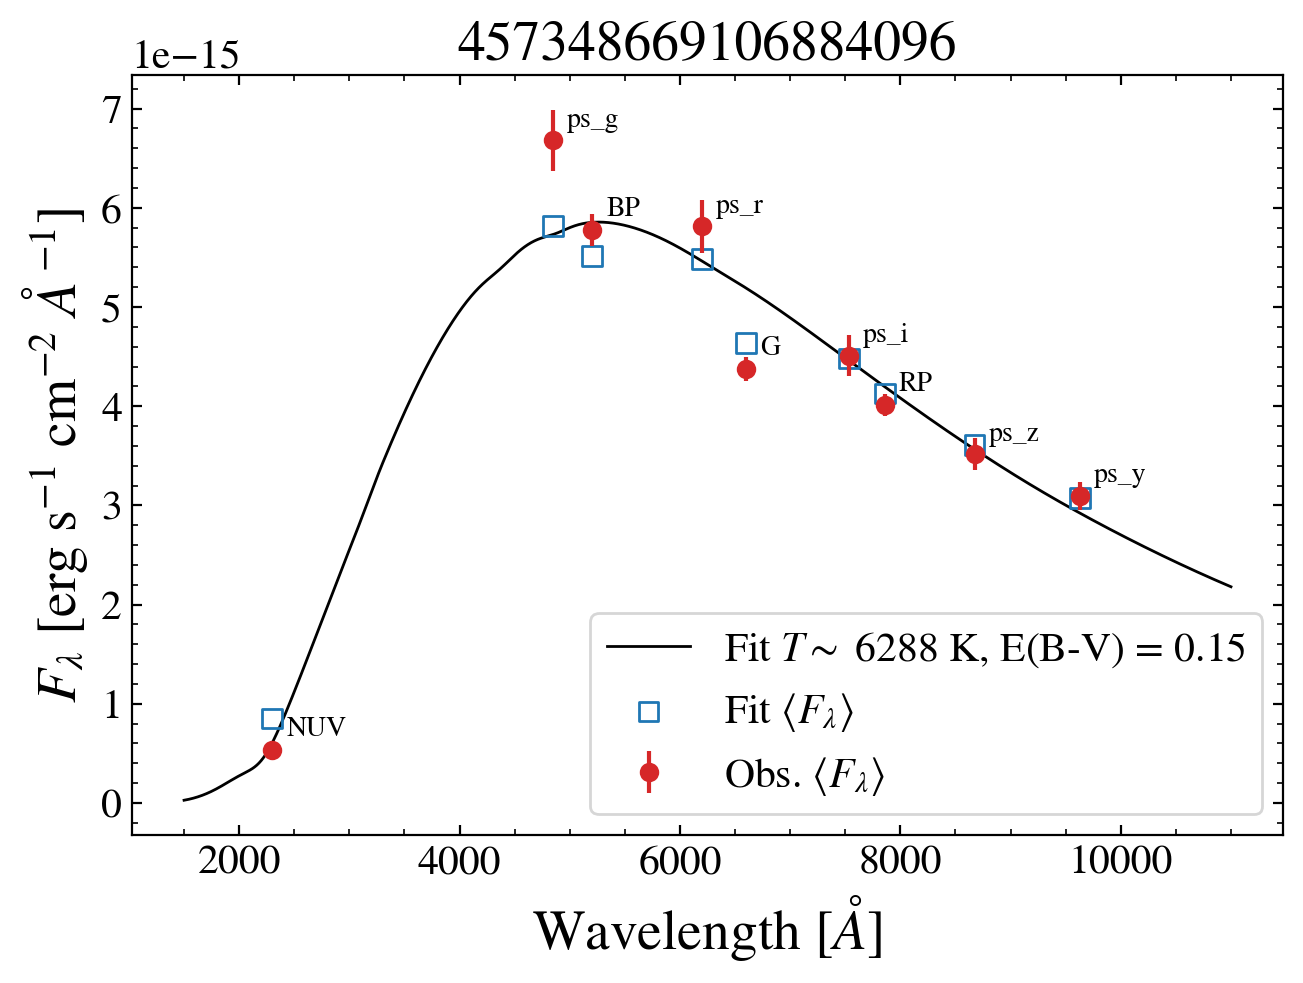

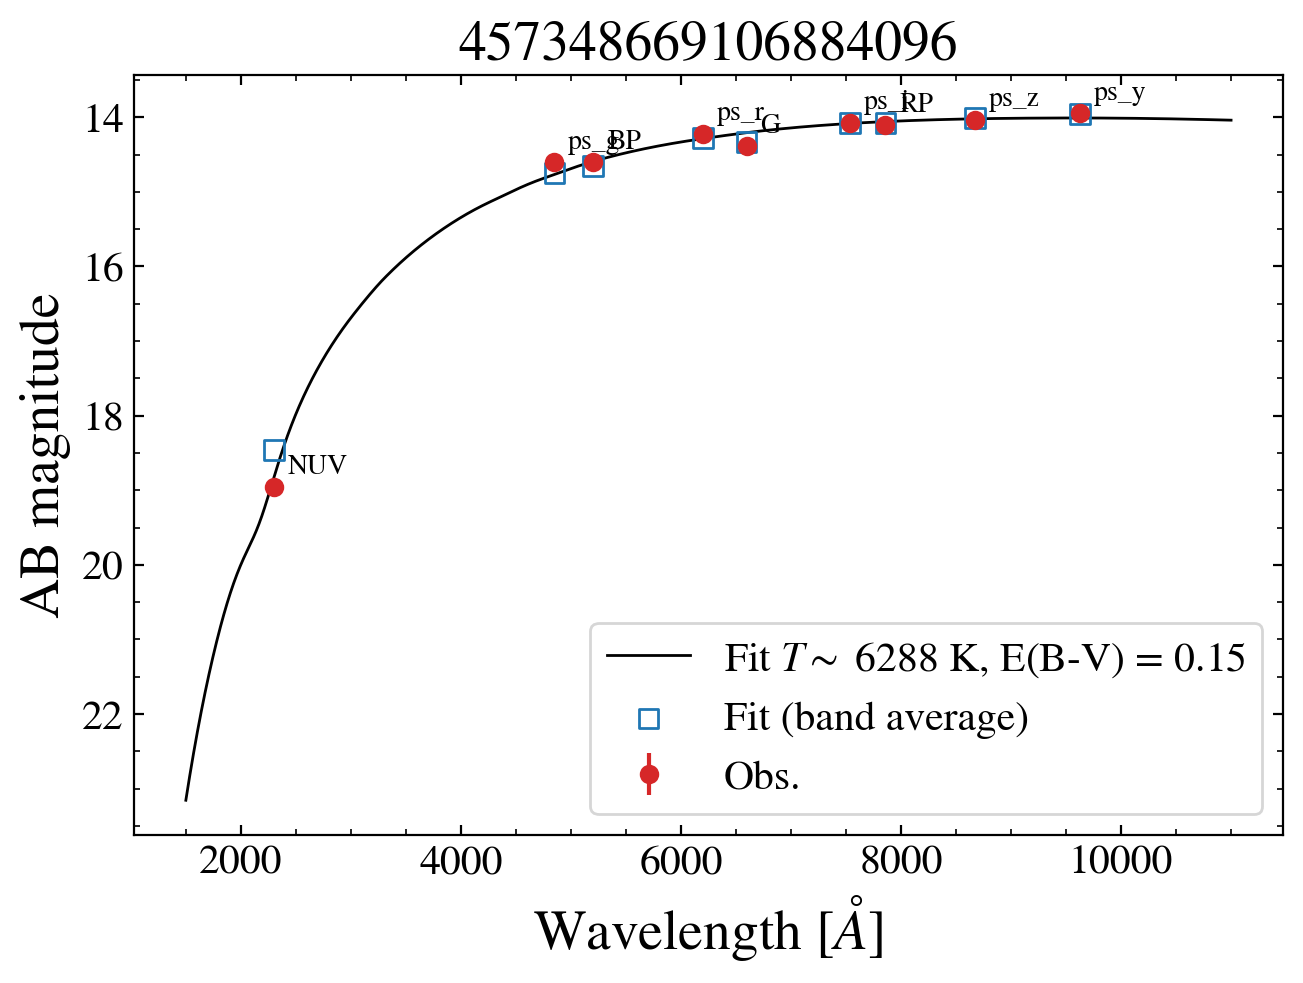

In [ ]:
_rng = np.random.default_rng()
fitted_idx = np.flatnonzero(np.isfinite(tbl_fov_fit['teff_fit']))
rng_idx = _rng.choice(fitted_idx)

_teff = tbl_fov_fit['teff_fit'][rng_idx]
_ebv = tbl_fov_fit['ebv_fit'][rng_idx]
_flux_scale = tbl_fov_fit['flux_scale_fit'][rng_idx]
_chi2 = tbl_fov_fit['chi2_fit'][rng_idx]
_obs_mags = obs_mag_all[rng_idx]
_obs_mag_errs = obs_mag_err_all[rng_idx]
_source_id = tbl_fov_fit['source_id'][rng_idx]
print(f'row {rng_idx}, source_id {tbl_fov_fit['source_id'][rng_idx]}, NUV ~{_obs_mags[0]:.2f}')

# Best-fit spectrum
best_sp = reddened_blackbody(_teff, _ebv, wave, ext_model) * _flux_scale
flux = best_sp(wave, flux_unit=units.FLAM)

print(f'Teff = {_teff:.0f} K, E(B-V) = {_ebv:.2f}, chi2 = {_chi2:.2f}')
print(f'model - observed [mag]: {synthetic_mags(best_sp, bandpasses, vega) - _obs_mags}')

in_range = (wave >= 1500 * u.AA) & (wave <= 11000 * u.AA)

pivots = np.array([bandpasses[name].pivot().to_value(u.AA) for name in BANDS]) # NOTE: The pivot wavelength, where F_lambda <-> F_nu

synth_mags = synthetic_mags(best_sp, bandpasses, vega)
synth_flam = np.array([Observation(best_sp, bandpasses[name])
                      .effstim(flux_unit=units.FLAM).value
                      for name in BANDS]) # Band-averaged Flux_lambda in each band

obs_flam = synth_flam * 10**(-0.4 * (_obs_mags - synth_mags)) # NOTE: F_obs = F_mdl * 10**(-4 * dmag)
obs_flam_err = obs_flam * _obs_mag_errs * np.log(10) / 2.5 # sig_Flux = Flux * sig_mag * log10/2.5

mag_ab = best_sp(wave, flux_unit=u.ABmag).value
synth_ab = np.array([Observation(best_sp, bandpasses[name])
                     .effstim(flux_unit=u.ABmag).value
                     for name in BANDS])
obs_ab = synth_ab + (_obs_mags - synth_mags)

fig = plt.figure(layout='constrained')
ax = fig.add_subplot()
print(obs_flam - synth_flam)
ax.plot(wave[in_range].to_value(u.AA), flux[in_range].value, color='k', lw=1,
        label=f'Fit $T\\sim$ {_teff:.0f} K, E(B-V) = {_ebv:.2f}')
ax.scatter(pivots, synth_flam, marker='s', s=50, facecolors='none',
           edgecolors='C0', zorder=3, label=f'Fit $\\left\\langle F_{{\\lambda}}\\right\\rangle$')
ax.errorbar(pivots, obs_flam, yerr=obs_flam_err, fmt='o', color='C3',
            zorder=4, label=f'Obs. $\\left\\langle F_{{\\lambda}}\\right\\rangle$')

for name, x, y in zip(BANDS, pivots, obs_flam):
    ax.annotate(name, (x, y), textcoords='offset points', xytext=(5, 5))

ax.set_xlabel(f'Wavelength [$\\AA$]')
ax.set_ylabel(f'$F_{{\\lambda}}$ [erg s$^{{-1}}$ cm$^{{-2}}$ $\\AA^{{-1}}$]')
ax.set_title(f'{_source_id}')
ax.legend()
plt.show()
clear_plt()

fig = plt.figure(layout='constrained')
ax = fig.add_subplot()
ok = in_range & np.isfinite(mag_ab)
ax.plot(wave[ok].to_value(u.AA), mag_ab[ok], color='k', lw=1,
        label=f'Fit $T\\sim$ {_teff:.0f} K, E(B-V) = {_ebv:.2f}')
ax.scatter(pivots, synth_ab, marker='s', s=50, facecolors='none',
           edgecolors='C0', zorder=3, label='Fit (band average)')
ax.errorbar(pivots, obs_ab, yerr=_obs_mag_errs, fmt='o', color='C3',
            zorder=4, label='Obs.')
for name, x, y in zip(BANDS, pivots, obs_ab):
    ax.annotate(name, (x, y), textcoords='offset points', xytext=(5, 5))
ax.invert_yaxis()
ax.set_xlabel(f'Wavelength [$\\AA$]')
ax.set_ylabel('AB magnitude')
ax.set_title(f'{_source_id}')
ax.legend()
plt.show()
clear_plt()
